# 🏦 Loan Approval Prediction (Credit Risk Assessment)

## 📌 Project Overview
This project aims to predict whether a commercial or retail loan application will be approved based on the applicant's demographic, credit, and financial profile. Following the **CRISP-DM** (Cross-Industry Standard Process for Data Mining) methodology, we develop and benchmark Machine Learning classification models to automate the credit evaluation process, mitigating default risk and accelerating loan decision-making.

## 🛠 Tech Stack
* **Language:** Python 3
* **Data Manipulation & Analysis:** Pandas, NumPy
* **Data Visualization:** Matplotlib, Seaborn
* **Machine Learning:** Scikit-learn (Logistic Regression, Random Forest, Support Vector Machine)
* **Model Persistence:** Pickle

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings

warnings.filterwarnings('ignore')
plt.style.use('ggplot')
sns.set_palette("viridis")

In [ ]:
# Load dataset using a portable relative path
import os
data_path = "data/loan_data.csv" if os.path.exists("data/loan_data.csv") else "train_u6lujuX_CVtuZ9i (1).csv"
loan_df = pd.read_csv(data_path)

# Drop the unique identifier as it does not contribute to predictive modeling
loan_df = loan_df.drop(columns=["Loan_ID"])

display(loan_df.head())

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 2️⃣ Data Understanding & Preparation
* Handling missing values (Imputation)
* Encoding categorical variables
* Checking class imbalance

In [3]:
# 1. Impute missing categorical values with the mode (most frequent value)
cat_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Credit_History"]
for col in cat_cols:
    loan_df[col] = loan_df[col].fillna(loan_df[col].mode()[0])

# 2. Impute missing numerical values with median (robust against outliers)
num_cols = ["LoanAmount", "Loan_Amount_Term"]
for col in num_cols:
    loan_df[col] = loan_df[col].fillna(loan_df[col].median())

# 3. Verify that zero missing values remain
print("Missing values after imputation:
", loan_df.isnull().sum())

Missing values after imputation:
 Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [4]:
# Standardize Dependents column ('3+' -> '3')
loan_df["Dependents"] = loan_df["Dependents"].replace("3+", "3")

# Label Encode categorical text features to numeric integers
le = LabelEncoder()
categorical_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Loan_Status"]

for col in categorical_cols:
    loan_df[col] = le.fit_transform(loan_df[col])

display(loan_df.head())

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,2,1
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,0
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,2,1
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,2,1
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,2,1


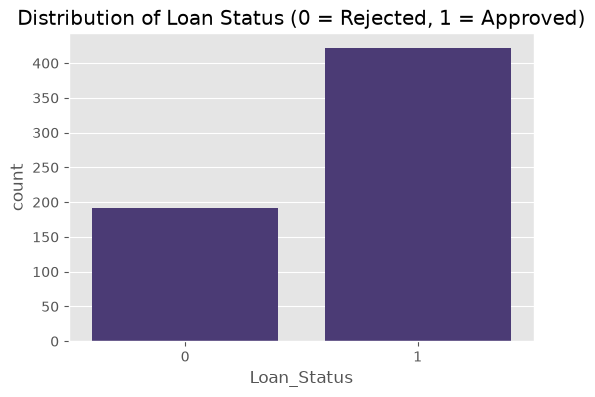

Loan_Status
1    68.729642
0    31.270358
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Loan_Status', data=loan_df)
plt.title("Distribution of Loan Status (0 = Rejected, 1 = Approved)")
plt.show()

print(loan_df['Loan_Status'].value_counts(normalize=True) * 100)

In [6]:
X = loan_df.drop(columns=["Loan_Status"])
y = loan_df["Loan_Status"]

# 80/20 train-test split stratified on target distribution
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Train size: (491, 11), Test size: (123, 11)


## 3️⃣ Model Training & Selection
We evaluate three competitive classification algorithms:
1. **Logistic Regression** (Linear baseline)
2. **Support Vector Machine (SVM)** (Maximum-margin separator)
3. **Random Forest Classifier** (Non-linear ensemble)

In [7]:
# 1. Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# 2. SVM
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

# 3. Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Models trained successfully!")

Models trained successfully!


## 4️⃣ Evaluation
Comparing models using Accuracy, Precision, Recall, and F1-Score.

In [8]:
def evaluate_model(y_true, y_pred, model_name):
    acc = accuracy_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)\n")
    print(classification_report(y_true, y_pred))
    print("-" * 50)

evaluate_model(y_test, lr_pred, "Logistic Regression")
evaluate_model(y_test, svm_pred, "Support Vector Machine (SVM)")
evaluate_model(y_test, rf_pred, "Random Forest")

--- Logistic Regression ---
Accuracy: 0.8618 (86.18%)

              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123

--------------------------------------------------
--- Support Vector Machine (SVM) ---
Accuracy: 0.8130 (81.30%)

              precision    recall  f1-score   support

           0       0.89      0.45      0.60        38
           1       0.80      0.98      0.88        85

    accuracy                           0.81       123
   macro avg       0.85      0.71      0.74       123
weighted avg       0.83      0.81      0.79       123

--------------------------------------------------
--- Random Forest ---
Accuracy: 0.8293 (82.93%)

              precision    recall  f1-score   support

           0       0.

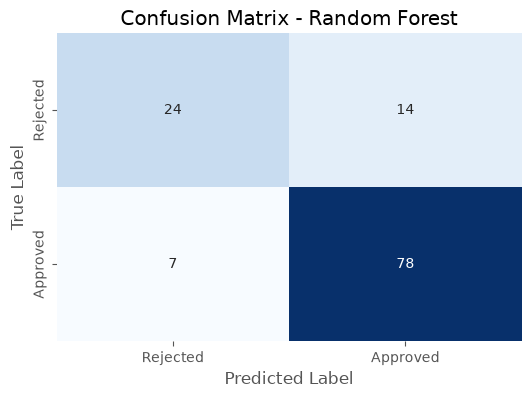

In [9]:
# Compute and plot Confusion Matrix for Random Forest
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Rejected", "Approved"],
            yticklabels=["Rejected", "Approved"])
plt.title("Confusion Matrix - Random Forest Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

## 5️⃣ Key Insights (Feature Importance)
Which features are the most important for loan approval?

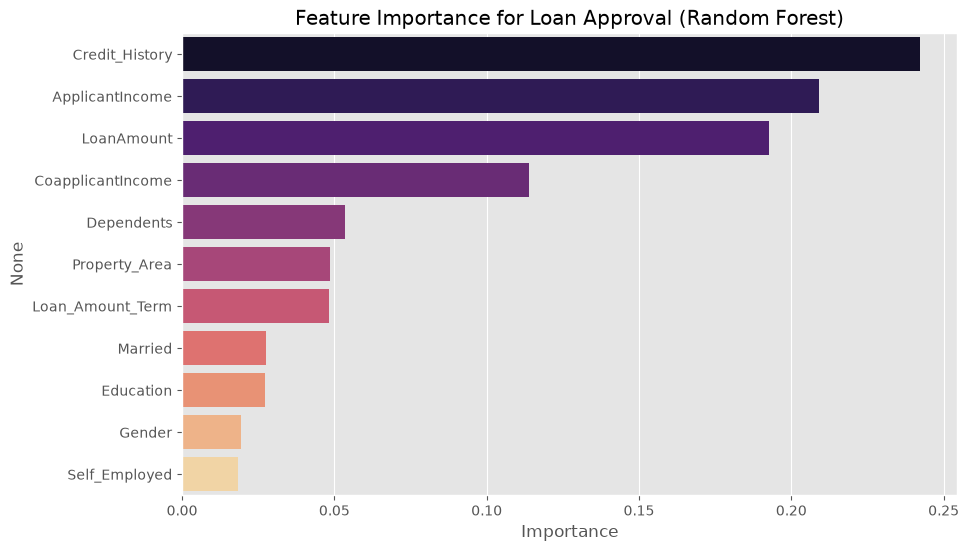

,Importance
Credit_History,0.242296
ApplicantIncome,0.209001
LoanAmount,0.192555
CoapplicantIncome,0.113800
Dependents,0.053360
Property_Area,0.048456
Loan_Amount_Term,0.048202
Married,0.027660
Education,0.027166
Gender,0.019237


In [10]:
# Extract feature importance weights from trained Random Forest
importances = pd.DataFrame(rf_model.feature_importances_, index=X.columns, columns=["Importance"]).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.Importance, y=importances.index, palette="magma")
plt.title("Feature Importance for Loan Approval (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

display(importances)

## 6️⃣ Deployment
Saving the best model for production.

In [11]:
import pickle

# Serialize the best model for production inference
with open("models/loan_approval_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

# Also maintain backward-compatible root model file
with open("loan_approval_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

print("Model successfully serialized to 'models/loan_approval_model.pkl' and 'loan_approval_model.pkl'!")

Model successfully saved as 'loan_approval_model.pkl'!
